In [1]:
import mudata
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
scplus_mdata = mudata.read("/home/rsun@ZHANGroup.local/sly_data/grn_momics/scenic_hm_outs/scenic_pipe/Snakemake/scplusmdata.h5mu")
scplus_mdata

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is depreca

MuData object with n_obs × n_vars = 19409 × 263328
  uns:	'direct_e_regulon_metadata', 'extended_e_regulon_metadata'
  6 modalities
    scRNA_counts:	19409 x 9911
      obs:	'leiden', 'eco', 'species', 'sample'
      var:	'gene_ids', 'feature_types', 'genome'
      obsm:	'X_pca', 'X_pca_harmony', 'X_umap'
    scATAC_counts:	19409 x 252091
      obs:	'sample', 'cisTopic_log_nr_acc', 'eco', 'cisTopic_nr_acc', 'barcode_rank', 'pdf_values_for_tss_enrichment', 'tss_enrichment', 'barcode', 'unique_fragments_in_peaks_count', 'log10_total_fragments_in_peaks_count', 'total_fragments_in_peaks_count', 'total_fragments_count', 'species', 'log10_total_fragments_count', 'cisTopic_nr_frag', 'cisTopic_log_nr_frag', 'pdf_values_for_fraction_of_fragments_in_peaks', 'pdf_values_for_duplication_ratio', 'nucleosome_signal', 'sample_id', 'duplication_ratio', 'log10_unique_fragments_in_peaks_count', 'duplication_count', 'log10_unique_fragments_count', 'unique_fragments_count', 'leiden', 'fraction_of_fragments_in_peaks', 'pycisTopic_leiden_10_1'
      var:	'Chromosome', 'Start', 'End', 'Width', 'cisTopic_nr_frag', 'cisTopic_log_nr_frag', 'cisTopic_nr_acc', 'cisTopic_log_nr_acc'
      obsm:	'UMAP'
    direct_gene_based_AUC:	19409 x 203
    direct_region_based_AUC:	19409 x 203
    extended_gene_based_AUC:	19409 x 460
    extended_region_based_AUC:	19409 x 460

## differential peaks

In [2]:
scdata = scplus_mdata['scATAC_counts']
scdata

AnnData object with n_obs × n_vars = 19409 × 252091
    obs: 'sample', 'cisTopic_log_nr_acc', 'eco', 'cisTopic_nr_acc', 'barcode_rank', 'pdf_values_for_tss_enrichment', 'tss_enrichment', 'barcode', 'unique_fragments_in_peaks_count', 'log10_total_fragments_in_peaks_count', 'total_fragments_in_peaks_count', 'total_fragments_count', 'species', 'log10_total_fragments_count', 'cisTopic_nr_frag', 'cisTopic_log_nr_frag', 'pdf_values_for_fraction_of_fragments_in_peaks', 'pdf_values_for_duplication_ratio', 'nucleosome_signal', 'sample_id', 'duplication_ratio', 'log10_unique_fragments_in_peaks_count', 'duplication_count', 'log10_unique_fragments_count', 'unique_fragments_count', 'leiden', 'fraction_of_fragments_in_peaks', 'pycisTopic_leiden_10_1'
    var: 'Chromosome', 'Start', 'End', 'Width', 'cisTopic_nr_frag', 'cisTopic_log_nr_frag', 'cisTopic_nr_acc', 'cisTopic_log_nr_acc'
    obsm: 'UMAP'

step1 over
         Falling back to preprocessing with `sc.pp.pca` and default params.


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


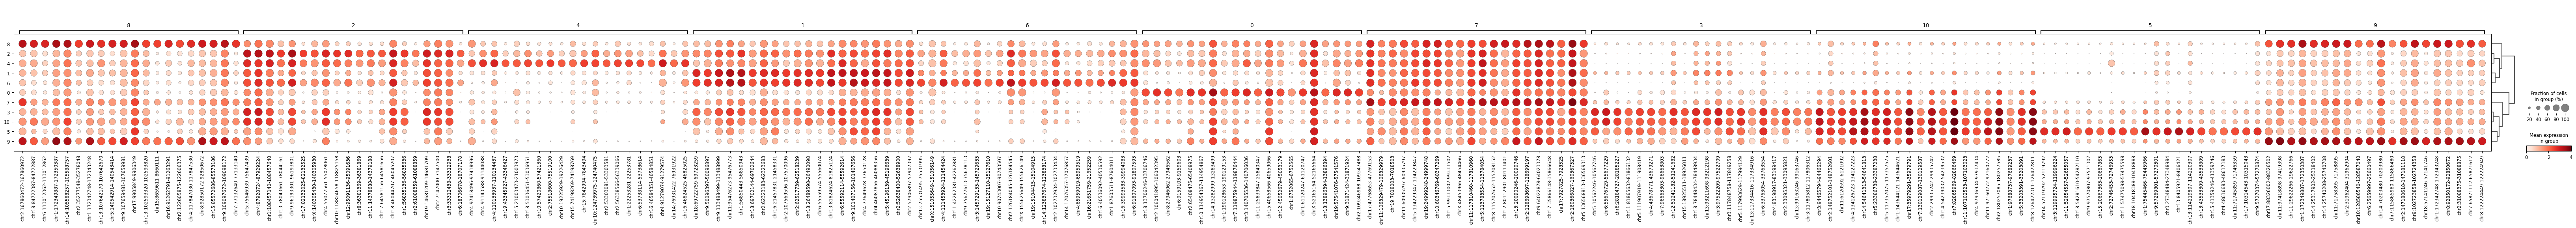

In [28]:
import scanpy as sc
sc.pp.normalize_total(scdata, target_sum = 1e6)
sc.pp.log1p(scdata)
print('step1 over')
sc.tl.rank_genes_groups(scdata, groupby = 'leiden')
sc.pl.rank_genes_groups_dotplot(scdata, groupby = 'leiden', n_genes = 20)


## 差异调控分析

### 调控模块heatmap

In [2]:
import scanpy as sc
import anndata

grn = scplus_mdata.uns['direct_e_regulon_metadata']
grn_e = scplus_mdata.uns['extended_e_regulon_metadata']
print(grn.shape, grn_e.shape)

(25257, 15) (54257, 15)


#### 分别获取 基于tg 的 调控模块 和基于 re的调控模块

In [3]:
from scenicplus.RSS import (regulon_specificity_scores, plot_rss)

rss_tf = regulon_specificity_scores(
    scplus_mudata = scplus_mdata,
    variable = "scRNA_counts:leiden",
    modalities = ["direct_gene_based_AUC"]#, "extended_gene_based_AUC"]
)

rss_re = regulon_specificity_scores(
    scplus_mudata = scplus_mdata,
    variable = "scRNA_counts:leiden",
    modalities = ["direct_region_based_AUC"]#, "extended_gene_based_AUC"]
)

rss_idx = [str(i) for i in range(11)]
rss_tf = rss_tf.loc[rss_idx, :]
rss_re = rss_re.loc[rss_idx, :]

print(rss_tf.shape, rss_re.shape)

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/scenicplus/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


(11, 203) (11, 203)


#### 调控模块rename 

将模块统一为TF(+/-) 的形式， 将 +/+ 转为 +, 将 -/- 转为 -

In [4]:
# filter:

sel_id = []
new_col = []

for key in rss_tf.columns:
    x = key.split('_')
    if x[2] == '+/+':
        sel_id.append(True)
        new_col.append(f'{x[0]}(+)')
    elif x[2] == '-/-':
        sel_id.append(True)
        new_col.append(f'{x[0]}(-)')
    else:
        sel_id.append(False)

rss_tf = rss_tf.loc[:,sel_id]
rss_tf.columns = new_col
print(rss_tf.shape)


sel_id = []
new_col = []

for key in rss_re.columns:
    x = key.split('_')
    if x[2] == '+/+':
        sel_id.append(True)
        new_col.append(f'{x[0]}(+)')
    elif x[2] == '-/-':
        sel_id.append(True)
        new_col.append(f'{x[0]}(-)')
    else:
        sel_id.append(False)

rss_re = rss_re.loc[:,sel_id]
rss_re.columns = new_col
print(rss_re.shape)

assert (rss_re.columns == rss_tf.columns).all()


(11, 99)
(11, 99)


#### 调控模块merge

rss = sqrt(rss_tf * rss_tg)

In [5]:
rss = np.sqrt(rss_re * rss_tf)
rss

,Arnt(-),Arx(+),Bach2(+),Bach2(-),Bhlhe22(+),Bhlhe22(-),Cebpb(+),Cebpd(+),Cebpg(+),Chd2(+),...,Sp5(+),Sp7(+),Spi1(+),Tbr1(+),Tef(+),Tef(-),Usf1(+),Zeb1(+),Zeb1(-),Zfx(+)
0,0.328682,0.214265,0.232677,0.470744,0.478146,0.415772,0.217340,0.423968,0.288854,0.391478,...,0.278107,0.246698,0.279852,0.238602,0.346778,0.378840,0.427296,0.335426,0.380332,0.379959
1,0.302824,0.222816,0.343994,0.244241,0.235850,0.271891,0.228392,0.233748,0.276446,0.293029,...,0.230400,0.241011,0.247675,0.315772,0.297475,0.298958,0.265997,0.329166,0.298323,0.291424
2,0.283930,0.188123,0.243863,0.229021,0.214322,0.251327,0.194313,0.202085,0.247523,0.265583,...,0.259669,0.217198,0.227998,0.245898,0.302533,0.275277,0.222812,0.323666,0.282344,0.305645
3,0.280699,0.213609,0.352596,0.239725,0.291938,0.255456,0.273683,0.279860,0.293568,0.283423,...,0.206320,0.210117,0.214031,0.222775,0.264332,0.261485,0.304667,0.229582,0.255211,0.243220
4,0.262086,0.199125,0.229637,0.205552,0.210849,0.252708,0.190097,0.213683,0.220682,0.241739,...,0.218340,0.207991,0.215018,0.247339,0.266693,0.225509,0.205252,0.280886,0.251755,0.262361
5,0.270416,0.228907,0.200367,0.248881,0.251473,0.241804,0.415144,0.285540,0.316835,0.241242,...,0.193321,0.198579,0.204580,0.193509,0.286181,0.204503,0.258977,0.219616,0.229891,0.230717
6,0.225816,0.183694,0.202200,0.190669,0.181800,0.216211,0.183659,0.180320,0.212594,0.218217,...,0.210677,0.205210,0.206784,0.327743,0.232281,0.224540,0.193651,0.262627,0.228286,0.242620
7,0.234387,0.224059,0.229519,0.221832,0.221660,0.223059,0.230300,0.226759,0.230165,0.240232,...,0.203392,0.203301,0.398016,0.201252,0.231314,0.215863,0.240851,0.230127,0.230066,0.236585
8,0.227113,0.298044,0.212267,0.210537,0.203791,0.216930,0.223996,0.202016,0.206892,0.231918,...,0.207410,0.207874,0.208823,0.229453,0.235432,0.197258,0.218470,0.231070,0.220583,0.230377
9,0.208716,0.188508,0.209229,0.206842,0.208974,0.197403,0.231621,0.208892,0.215361,0.209020,...,0.187275,0.196241,0.192684,0.179754,0.209408,0.188061,0.223971,0.192677,0.201599,0.206271


In [ ]:
rss.to_csv('rss_new.csv')

In [327]:
rna = scplus_mdata['scRNA_counts']

tf_list = rss.columns.values.copy() 
for i,ele in enumerate(tf_list):
    tf_list[i] = ele.split('(')[0]
X = rna[:,tf_list]

data_list = []
for i in range(11):
    subdata = X[X.obs.leiden == str(i),:]
    data_list.append(subdata.X.mean(0))
tf_exp = pd.DataFrame(data_list, columns = rss.columns.values , index = [str(i) for i in range(11)])
tf_exp.to_csv('tf_exp.csv')

#### 调控模块heatmap

33


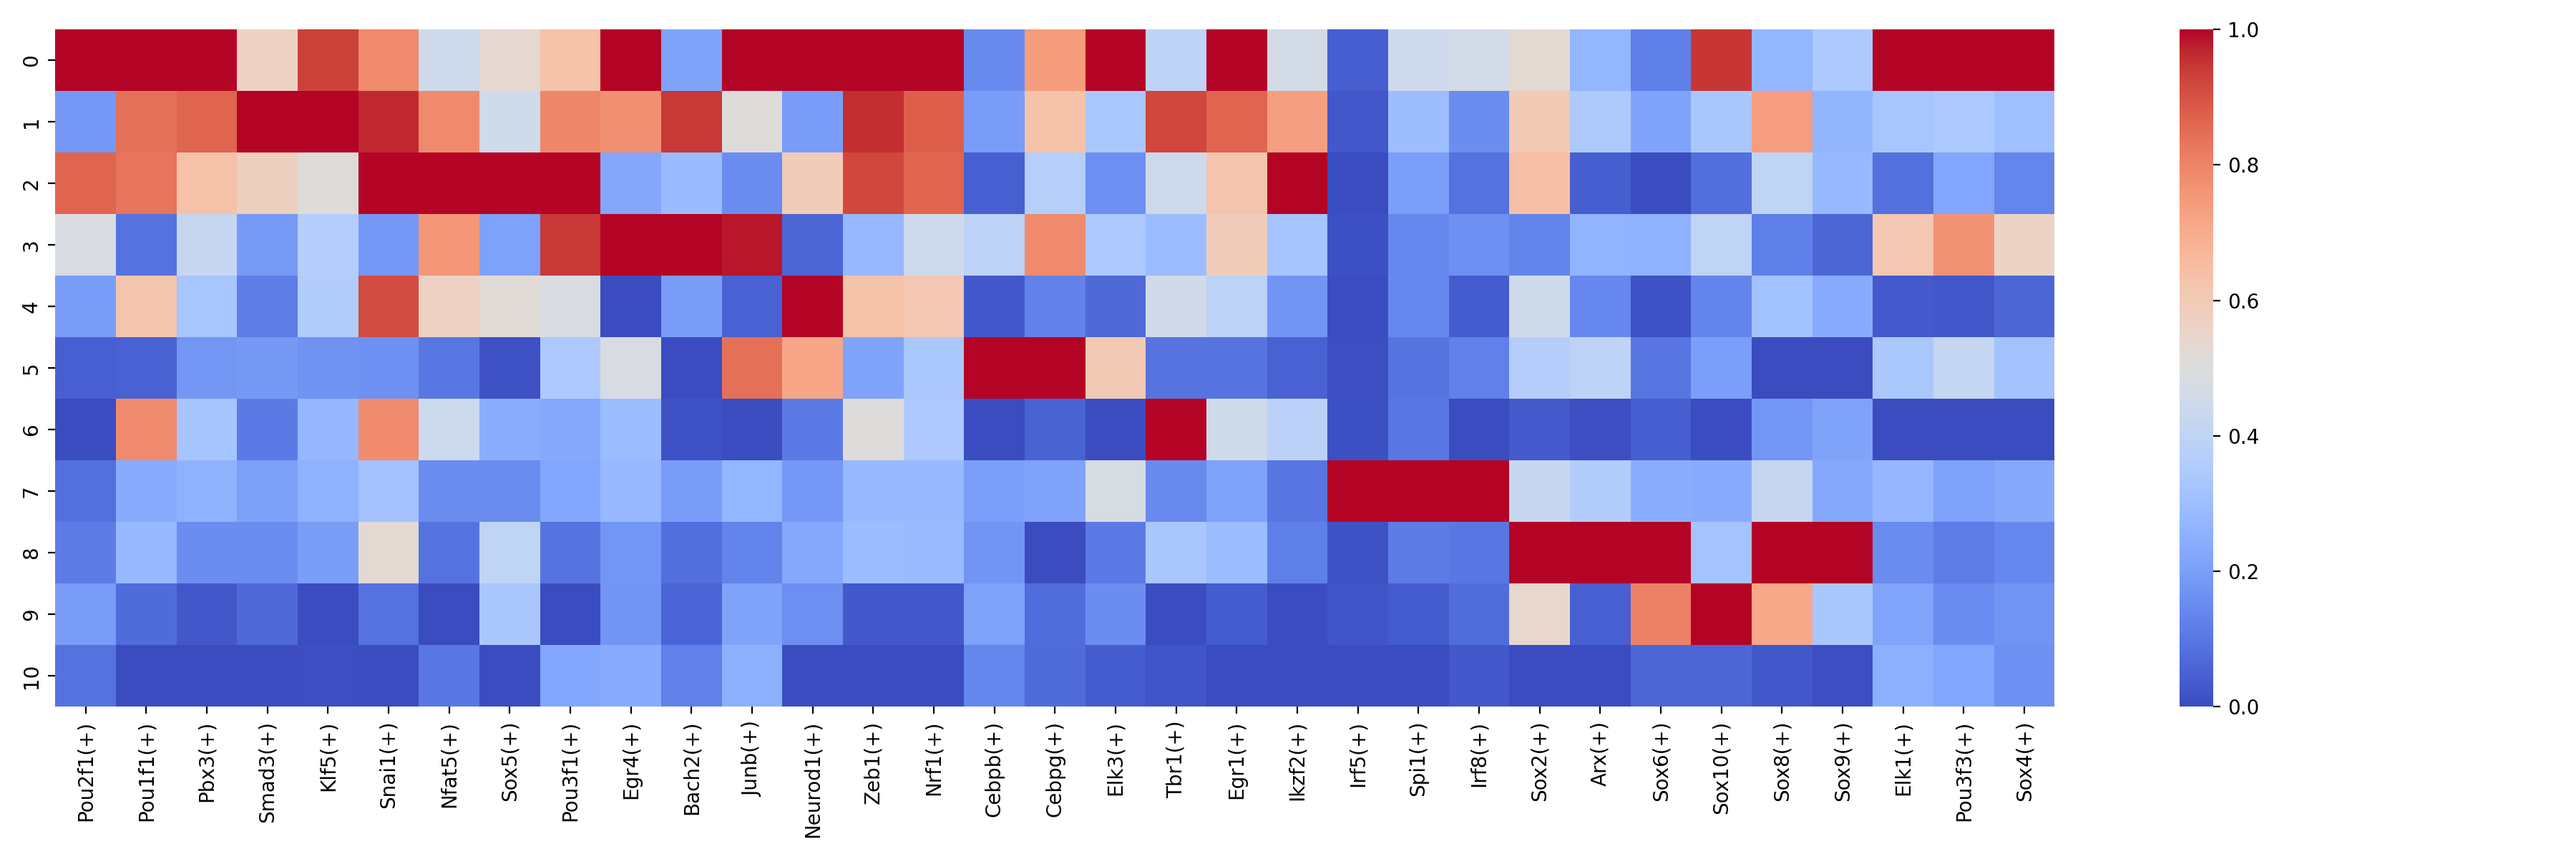

In [203]:
## rss min_max scaler

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

rss = pd.DataFrame(scaler.fit_transform(rss), index = rss.index, columns = rss.columns)

## 获取每个cluster中rss分数最高的一组 

module_list = []
for i in range(11):
    tmp = rss.loc[str(i),:]
    tmp = tmp.sort_values(ascending = False)
    count = 0
    for j in range(50):
        x = tmp.index[j]
        if x not in module_list and '+' in x:
            module_list.append(x)
            count += 1
        if count == 3:
            break

module_list = np.array(module_list)
#module_list = np.unique(module_list, sorted = False)
print(len(module_list))

sub_rss = rss.loc[:,module_list] 
plt.figure(figsize = (18,6))
sns.heatmap(sub_rss, cmap = 'coolwarm')
plt.show() 
